In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1.370545e+06,816056.169852,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.152836e+00,2.194865,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,4.806278e+02,5944.124151,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,8.924381e+01,345.608862,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,2.589699e+01,240.483727,0.0,0.00,0.00,0.00,50000.0


In [6]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

## Data Quality Check

The dataset contains 2,443,651 product listings and 9 variables.

After inspecting the data:
- No missing values were found.
- No duplicated rows were identified.
- Data types were already correctly assigned.

Therefore, no additional cleaning steps were required before performing the exploratory analysis.

## Part 1: Understanding Product Categories

frequency table for the product category

In [8]:
category_frequency = df["category"].value_counts()
category_frequency.head(10)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64

In [9]:
top_5_categories = df["category"].value_counts().head(5)
top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

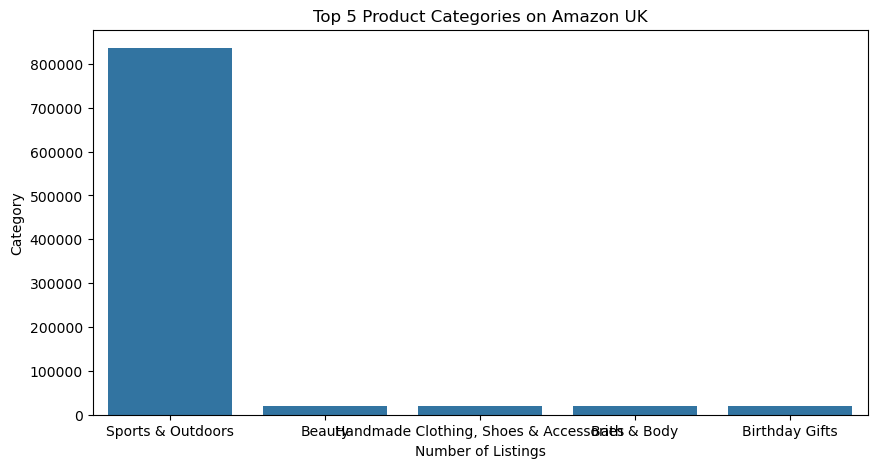

In [10]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_5_categories.index, y=top_5_categories.values)
plt.title("Top 5 Product Categories on Amazon UK")
plt.xlabel("Number of Listings")
plt.ylabel("Category")
plt.show()

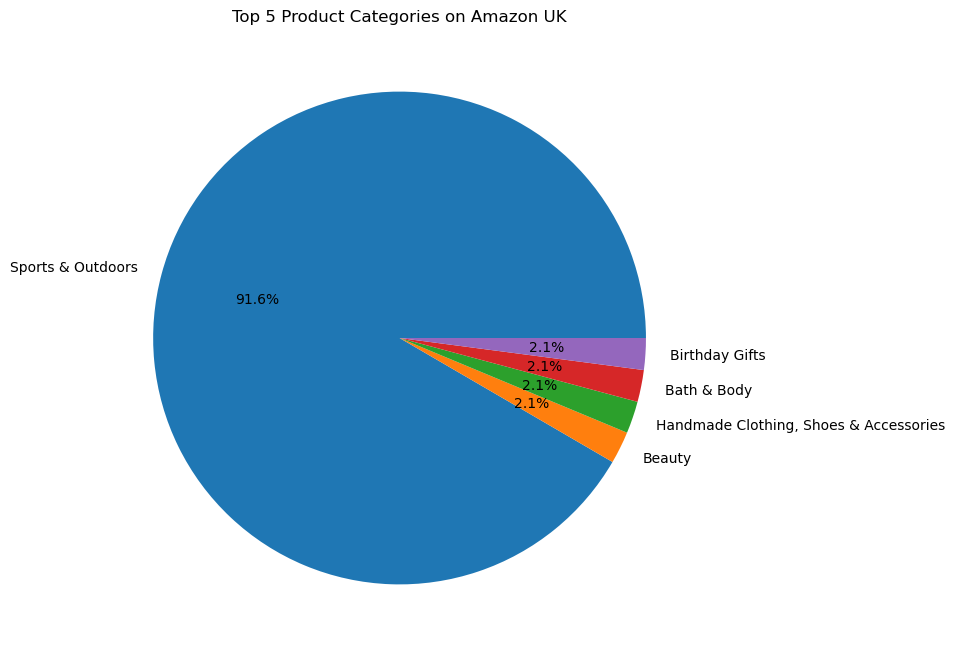

In [11]:
plt.figure(figsize=(8, 8))
top_5_categories.plot(kind="pie", autopct="%1.1f%%")
plt.title("Top 5 Product Categories on Amazon UK")
plt.ylabel("")
plt.show()

### Insights

The Amazon UK product listings are highly concentrated in the Sports & Outdoors category, which contains significantly more listings than any other category. This suggests that this segment has a very large marketplace presence and potentially higher competition among sellers.

The remaining top categories are considerably smaller and are mainly concentrated around beauty and personal care products, indicating that these segments also have strong representation but at a much lower scale.

The dominance of Sports & Outdoors may influence marketplace strategies, such as inventory planning, seller competition analysis, and category-specific marketing decisions.

## Part 2: Delving into Product Pricing

In [12]:
#The average price of all products listed on Amazon UK.
mean_price = df["price"].mean()
mean_price

np.float64(89.24380943923661)

In [13]:
#The middle price point.
median_price = df["price"].median()
median_price

np.float64(19.09)

In [14]:
#The most frequent price.
mode_price = df["price"].mode()
mode_price

0    9.99
Name: price, dtype: float64

In [15]:
mode_price = df["price"].mode()[0]
mode_price

np.float64(9.99)

In [16]:
price_centrality = pd.DataFrame({
    "Measure": ["Mean", "Median", "Mode"],
    "Price": [
        mean_price,
        median_price,
        mode_price
    ]
})

price_centrality

,Measure,Price
0,Mean,89.243809
1,Median,19.090000
2,Mode,9.990000


### Central Tendency Insights

The analysis of product prices shows a considerable difference between the mean (89.24) and the median (19.09). This indicates that the distribution is not symmetrical and is likely influenced by a smaller number of high-priced products.

The mode (9.99) suggests that lower-priced products are the most frequently listed on Amazon UK, meaning that the majority of products are positioned within an affordable price range.

The large gap between the mean and median indicates the presence of premium products with much higher prices, which increase the overall average.

In [17]:
#Variance
price_variance = df["price"].var()
price_variance

np.float64(119445.48532254901)

In [18]:
#Standard deviation
price_std = df["price"].std()
price_std

np.float64(345.60886175349873)

In [19]:
#Range
price_range = df["price"].max() - df["price"].min()
price_range

np.float64(100000.0)

In [20]:
#Interquartile range (IQR)
Q1 = df["price"].quantile(0.25)

Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

IQR

np.float64(36.0)

In [21]:
price_dispersion = pd.DataFrame({
    "Measure": [
        "Variance",
        "Standard Deviation",
        "Range",
        "Interquartile Range"
    ],
    "Value": [
        price_variance,
        price_std,
        price_range,
        IQR
    ]
})

price_dispersion

,Measure,Value
0,Variance,119445.485323
1,Standard Deviation,345.608862
2,Range,100000.000000
3,Interquartile Range,36.000000


### Measures of Dispersion Insights

The analysis of price dispersion shows that Amazon UK product prices have a very high level of variability.

The standard deviation (345.61) is considerably larger than the average price (89.24), indicating that prices are widely spread across different product segments.

The large range (100000) reveals the presence of extreme high-priced products that significantly affect the overall distribution. However, the interquartile range (36) suggests that the majority of products are concentrated within a much smaller price interval.

These results indicate that Amazon UK has a strongly right-skewed pricing distribution, where most products are relatively affordable but a small number of premium products create substantial price variation.

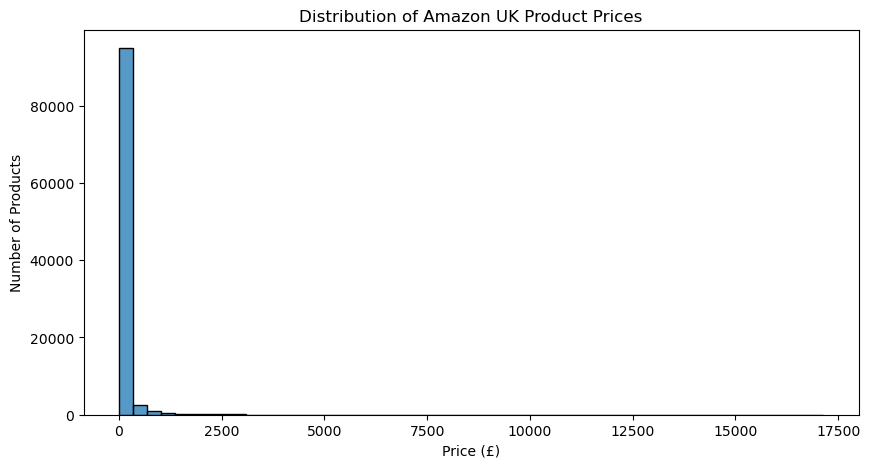

In [22]:
#Visualizations
price_sample = df["price"].sample(100000, random_state=42)

plt.figure(figsize=(10,5))

sns.histplot(
    price_sample,
    bins=50
)

plt.title("Distribution of Amazon UK Product Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")

plt.show()

### Histogram Interpretation

The histogram shows that most Amazon UK products are concentrated within lower price ranges, with a large number of listings appearing at relatively affordable prices.

However, the distribution is difficult to interpret because a small number of extremely expensive products extend the price range considerably. These outliers compress the majority of products into a smaller area of the histogram, making the common price ranges harder to visualize.

To improve readability, the analysis can focus on the price range where most products are located or use a logarithmic scale to reduce the effect of extreme values while keeping all observations included.

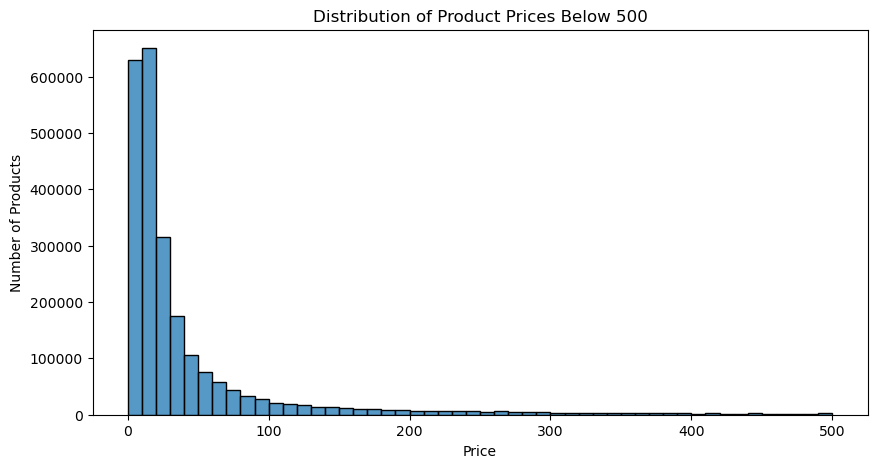

In [24]:
#Since the median is 19.09
price_under_500 = df[df["price"] < 500]["price"]

plt.figure(figsize=(10,5))

sns.histplot(
    price_under_500,
    bins=50
)

plt.title("Distribution of Product Prices Below 500")
plt.xlabel("Price")
plt.ylabel("Number of Products")

plt.show()

### Adjusted Histogram Interpretation

After limiting the visualization to products below 500, the distribution becomes clearer. The majority of products are concentrated within the lower price ranges, confirming that most Amazon UK listings are relatively affordable.

The comparison between the original and adjusted histogram shows that extreme prices have a strong influence on the overall distribution.

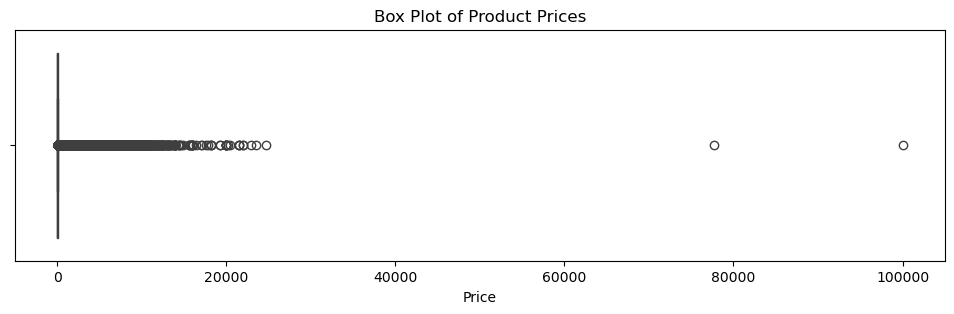

In [25]:
plt.figure(figsize=(12, 3))

sns.boxplot(x=df["price"])

plt.title("Box Plot of Product Prices")
plt.xlabel("Price")

plt.show()

## Box Plot interpretation

The box plot shows that product prices are highly right-skewed. Most products are concentrated within a relatively low price range, while a large number of high-priced products appear as outliers. These outliers explain why the mean price (89.24) is much higher than the median (19.09), indicating that a small number of expensive products strongly influence the average price.

### Part 3: Unpacking Product Ratings

In [28]:
df["stars"]

0          4.7
1          4.7
2          4.7
3          4.7
4          4.6
          ... 
2443646    0.0
2443647    0.0
2443648    0.0
2443649    4.3
2443650    4.5
Name: stars, Length: 2443651, dtype: float64

In [29]:
mean_rating = df["stars"].mean()
mean_rating

np.float64(2.152836472966066)

In [30]:
median_rating = df["stars"].median()
median_rating

np.float64(0.0)

In [32]:
mode_rating = df["stars"].mode()[0]
mode_rating

np.float64(0.0)

In [33]:
rating_centrality = pd.DataFrame({
    "Measure": ["Mean", "Median", "Mode"],
    "Rating": [
        mean_rating,
        median_rating,
        mode_rating
    ]
})

rating_centrality

,Measure,Rating
0,Mean,2.152836
1,Median,0.000000
2,Mode,0.000000


In [34]:
(df["stars"] == 0).sum()

np.int64(1225641)

In [35]:
(df["stars"] > 0).sum()

np.int64(1218010)

### Measures of Centrality Insights

The average product rating is **2.15 stars**, while both the **median** and **mode** are **0.0 stars**.

Further investigation shows that approximately **50.2%** of the products have a rating of **0.0**, suggesting that these products have not yet received any customer ratings rather than representing actual zero-star reviews.

As a result, the large number of unrated products lowers the overall average and makes the central tendency measures less representative of customer satisfaction. To better understand how customers evaluate products, it would be appropriate to perform a separate analysis using only products with ratings greater than zero.

In [36]:
rating_variance = df["stars"].var()
rating_std = df["stars"].std()

Q1 = df["stars"].quantile(0.25)
Q3 = df["stars"].quantile(0.75)
rating_iqr = Q3 - Q1

rating_skewness = df["stars"].skew()
rating_kurtosis = df["stars"].kurt()

In [37]:
print(f"Variance: {rating_variance}")
print(f"Standard Deviation: {rating_std}")
print(f"Interquartile Range: {rating_iqr}")
print(f"Skewness: {rating_skewness}")
print(f"Kurtosis: {rating_kurtosis}")

Variance: 4.817434029796864
Standard Deviation: 2.194865378513421
Interquartile Range: 4.4
Skewness: 0.08120735761080881
Kurtosis: -1.9260061280432994


### Measures of Dispersion Insights

The standard deviation of **2.19** indicates a relatively high variation in product ratings. This is mainly due to the large number of products with a rating of **0.0**, while many rated products receive much higher scores.

The interquartile range (IQR) of **4.40** shows that the middle 50% of the ratings span a wide portion of the rating scale. Overall, customer ratings are not tightly clustered, reflecting the coexistence of many unrated products and many highly rated products.

### Shape of the Distribution

The skewness of **0.08** is very close to zero, indicating that the overall distribution is approximately symmetrical.

The kurtosis of **-1.93** indicates a flatter distribution than a normal distribution (platykurtic), meaning that the ratings are spread across the scale rather than being highly concentrated around the mean.

However, these measures should be interpreted with caution because around half of the products have a rating of **0.0**, which likely represents unrated products rather than actual customer evaluations.

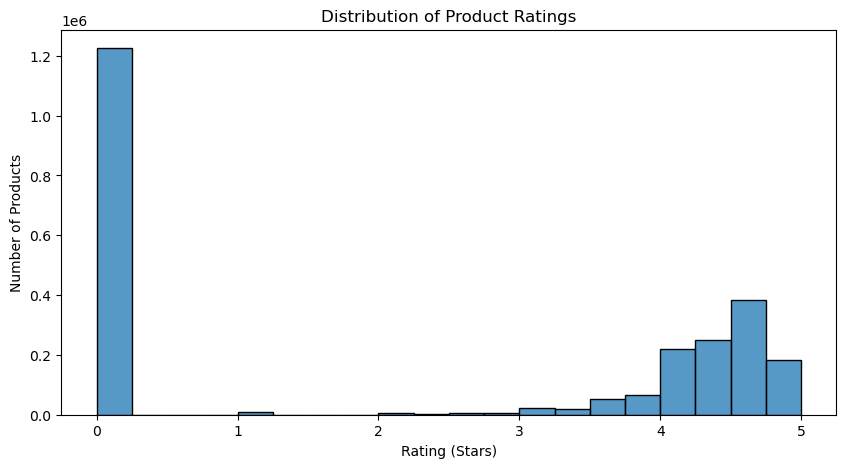

In [38]:
#Histogram
plt.figure(figsize=(10,5))

sns.histplot(df["stars"], bins=20)

plt.title("Distribution of Product Ratings")
plt.xlabel("Rating (Stars)")
plt.ylabel("Number of Products")

plt.show()

### Histogram Interpretation

The histogram shows a very large number of products with a rating of **0.0**, indicating that many products have not yet received customer ratings.

Among the rated products, ratings are concentrated toward the upper end of the scale, suggesting that customers generally give positive reviews. The presence of many unrated products, however, strongly influences the overall distribution and the summary statistics.